In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from arch import arch_model
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV, PredefinedSplit
import warnings
warnings.filterwarnings('ignore')
import yfinance as yf

# Part 1: Importing Data and Preprocessing

We will first import our financial data from Python's built-in library and do some necessary preprocessing before moving on to working with feature selection and modeling processes. 

In [3]:
ticker = "GC=F" # Gold Futures

Gold = yf.download(  # The data used in this notebook was all imported from the yfinance library built into Python
    ticker,
    start = "2006-01-01",
    end = "2026-08-01",       
    interval = "1d",  # We use daily data
    auto_adjust = False,
    progress = False,
    multi_level_index = False
)

In [4]:
Gold.head()

,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2006-01-03,530.700012,530.700012,528.500000,518.599976,518.599976,7
2006-01-04,533.900024,533.900024,533.599976,533.500000,533.599976,8
2006-01-05,526.299988,526.299988,529.000000,526.000000,529.000000,10
2006-01-06,539.700012,539.700012,539.700012,539.700012,539.700012,10
2006-01-09,549.099976,549.099976,539.700012,539.700012,539.700012,10


In [5]:
Gold.drop(['Adj Close', 'High', 'Low', 'Open', 'Volume'], axis = 1, inplace = True) # Only daily close price will be used throughout
Gold.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 5176 entries, 2006-01-03 to 2026-07-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   5176 non-null   float64
dtypes: float64(1)
memory usage: 80.9 KB


In [6]:
Gold.isnull().sum() # Check for any missing values

Close    0
dtype: int64

In [7]:
Gold.index.duplicated().sum() # Check for any duplicated values

np.int64(0)

# Part 2: EDA and Feature Engineering

Graphing distributions and creating new features for model training

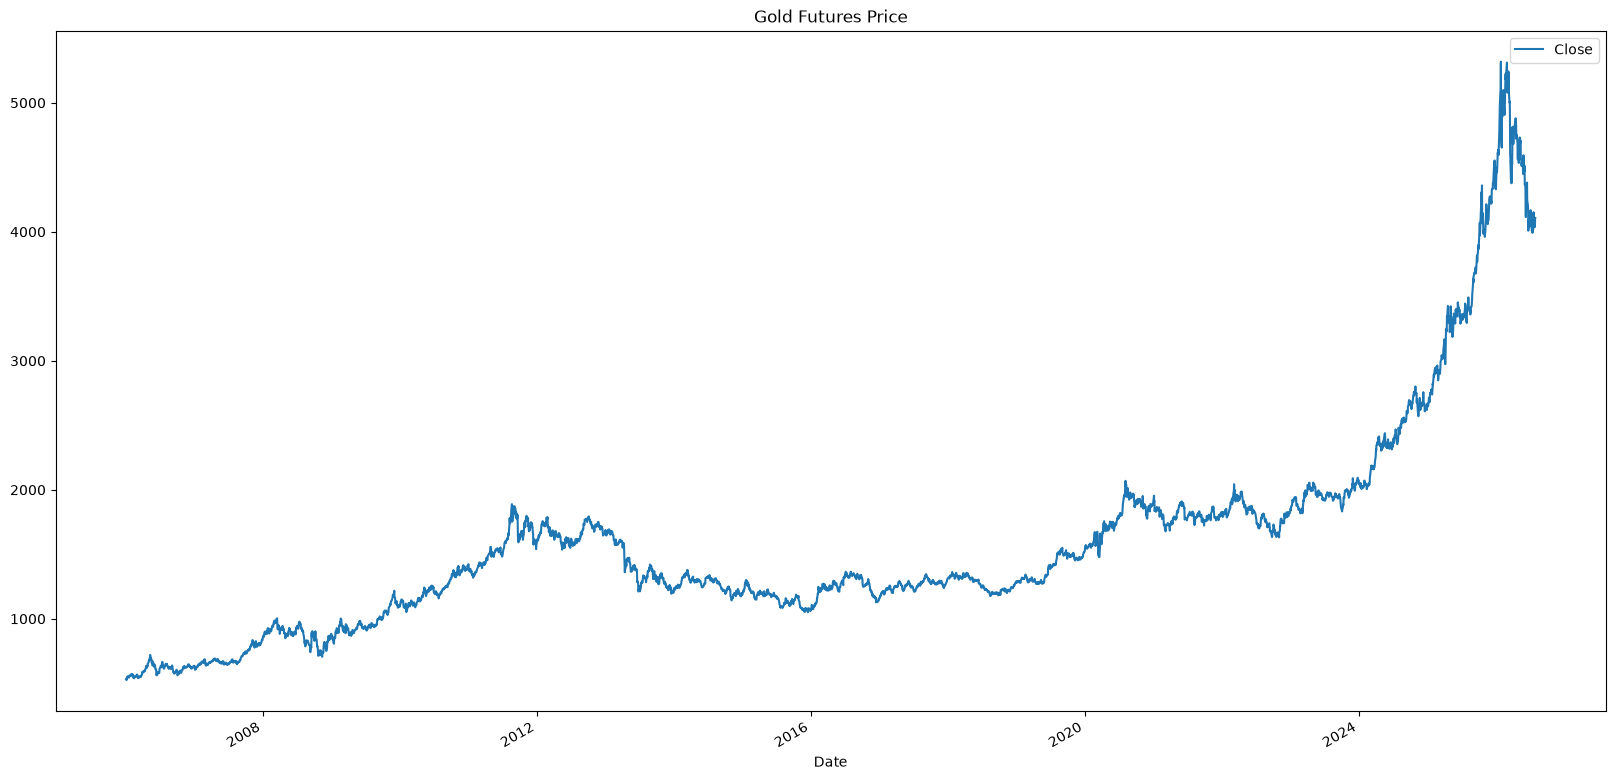

In [8]:
Gold.plot(y = 'Close', use_index = True, title = 'Gold Futures Price', figsize = (20, 10));

In [9]:
# Construct daily ordinary, absolute and squared returns used for later model training
Gold['Returns'] = 100 * np.log(Gold['Close']).diff()
Gold['Abs_Returns'] = Gold['Returns'].abs()
Gold['Squared_Returns'] = Gold['Returns'] ** 2

Gold.dropna(subset = ['Returns', 'Abs_Returns', 'Squared_Returns'], inplace = True)

Gold.head()

,Close,Returns,Abs_Returns,Squared_Returns
Date,,,,
2006-01-04,533.900024,0.601169,0.601169,0.361404
2006-01-05,526.299988,-1.433723,1.433723,2.055562
2006-01-06,539.700012,2.514208,2.514208,6.321243
2006-01-09,549.099976,1.726708,1.726708,2.981520
2006-01-10,544.299988,-0.877999,0.877999,0.770882


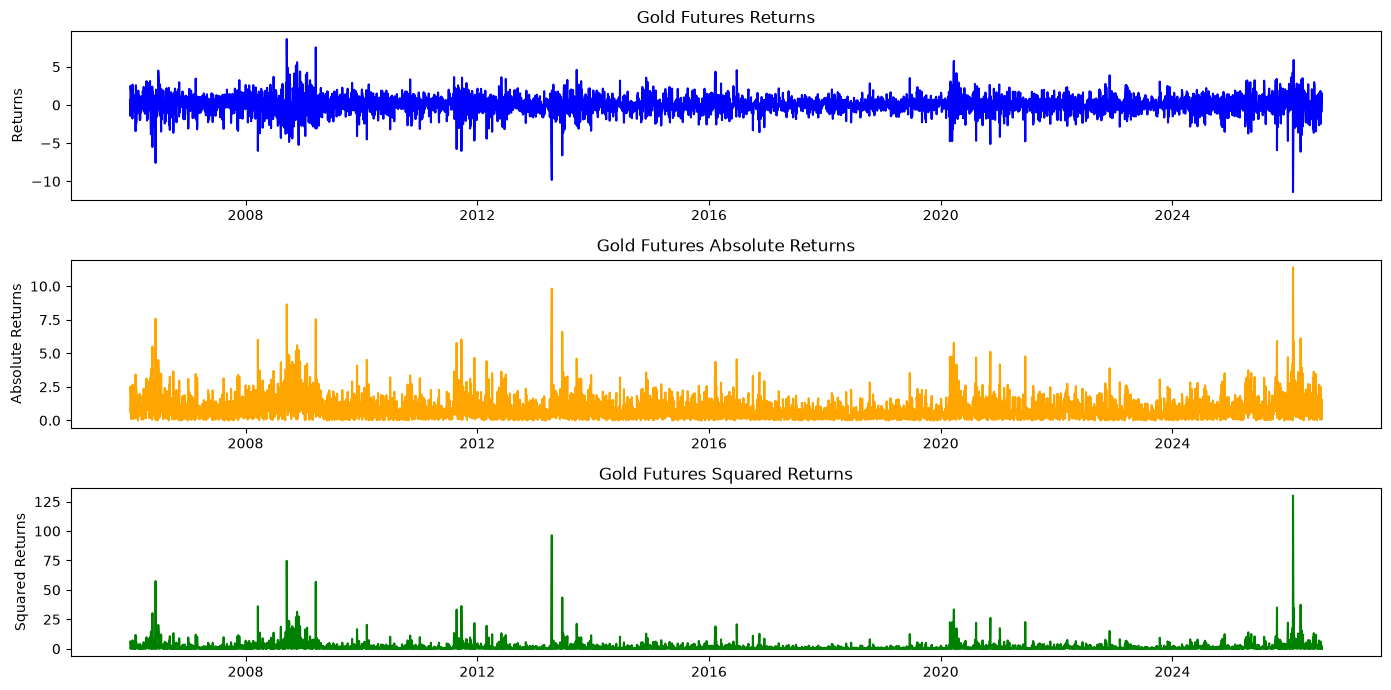

In [10]:
fig, ax = plt.subplots(3, 1, figsize = (14, 7))
ax[0].plot(Gold['Returns'], color = 'blue', label = 'Returns')
ax[0].set_title('Gold Futures Returns')
ax[0].set_ylabel('Returns')
ax[1].plot(Gold['Abs_Returns'], color = 'orange', label = 'Absolute Returns')
ax[1].set_title('Gold Futures Absolute Returns')
ax[1].set_ylabel('Absolute Returns')
ax[2].plot(Gold['Squared_Returns'], color = 'green', label = 'Squared Returns')
ax[2].set_title('Gold Futures Squared Returns')
ax[2].set_ylabel('Squared Returns')
plt.tight_layout()
plt.show()

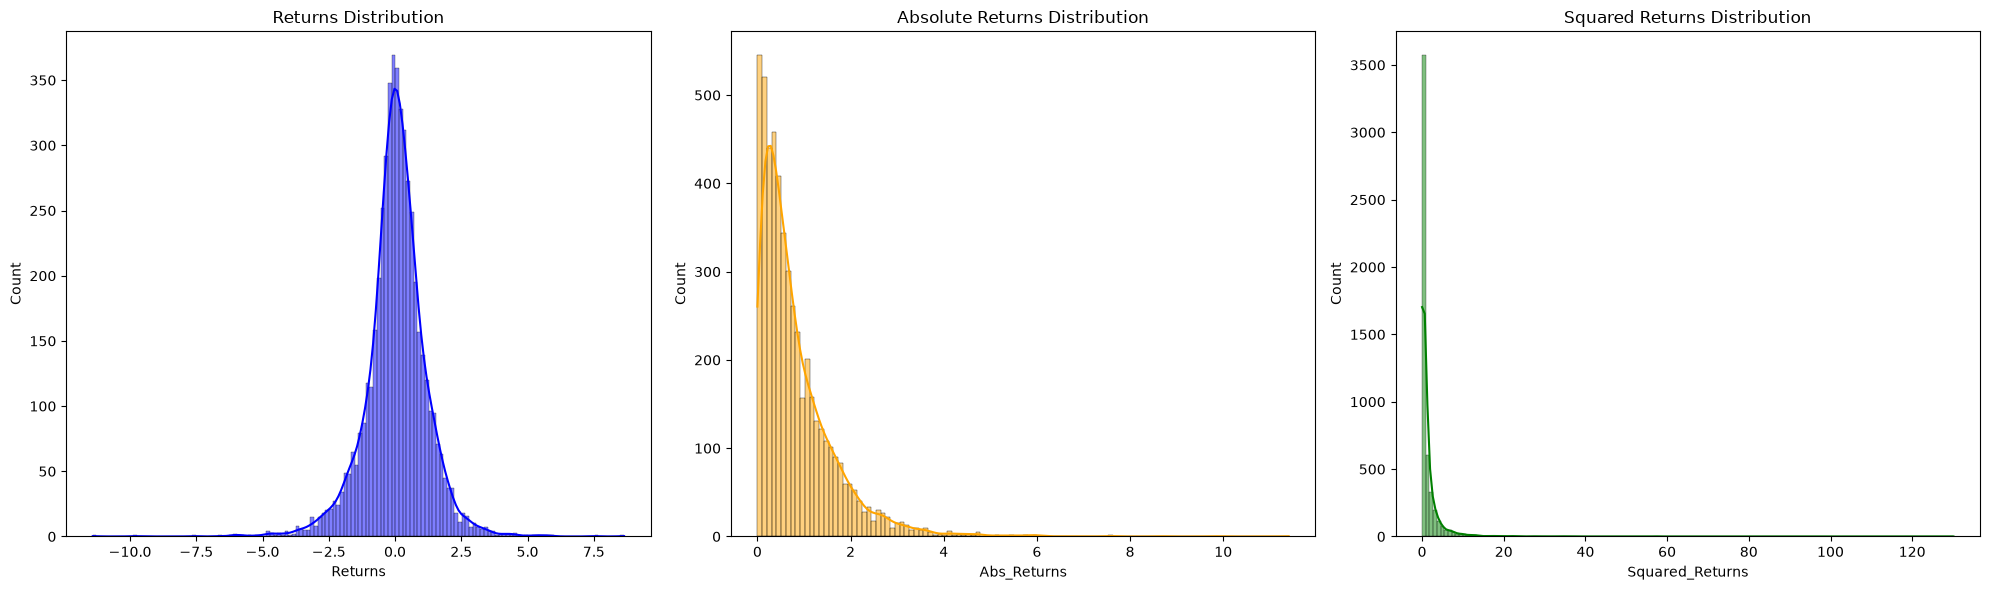

In [11]:
# Plot histogram distributions for each type of return
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
sns.histplot(data = Gold['Returns'], ax = ax[0], kde = True, color = 'blue', alpha = 0.5)
ax[0].set_title('Returns Distribution')
sns.histplot(data = Gold['Abs_Returns'], ax = ax[1], kde = True, color = 'orange', alpha = 0.5)
ax[1].set_title('Absolute Returns Distribution')
sns.histplot(data = Gold['Squared_Returns'], ax = ax[2], kde = True, color = 'green', alpha = 0.5)
ax[2].set_title('Squared Returns Distribution')
plt.tight_layout()
plt.show()

In [12]:
# Inspect skewness and Kurtosis from these distributions. This step can possibly inform the decision later on to select the distribution for the error term when computing volatility.
print(f'Returns Distribution skewness: {Gold["Returns"].skew():.4f}')
print(f'Absolute Returns Distribution skewness: {Gold["Abs_Returns"].skew():.4f}')
print(f'Squared Returns Distribution skewness: {Gold["Squared_Returns"].skew():.4f}')
print()
print(f'Returns Distribution kurtosis: {Gold["Returns"].kurtosis():.4f}')
print(f'Absolute Returns Distribution kurtosis: {Gold["Abs_Returns"].kurtosis():.4f}')
print(f'Squared Returns Distribution kurtosis: {Gold["Squared_Returns"].kurtosis():.4f}')

Returns Distribution skewness: -0.4927
Absolute Returns Distribution skewness: 2.7365
Squared Returns Distribution skewness: 13.8488

Returns Distribution kurtosis: 6.3381
Absolute Returns Distribution kurtosis: 15.0676
Squared Returns Distribution kurtosis: 325.5686


These values are fairly high, so rather than drawing on a normal distribution, we could use the student-t instead later on.

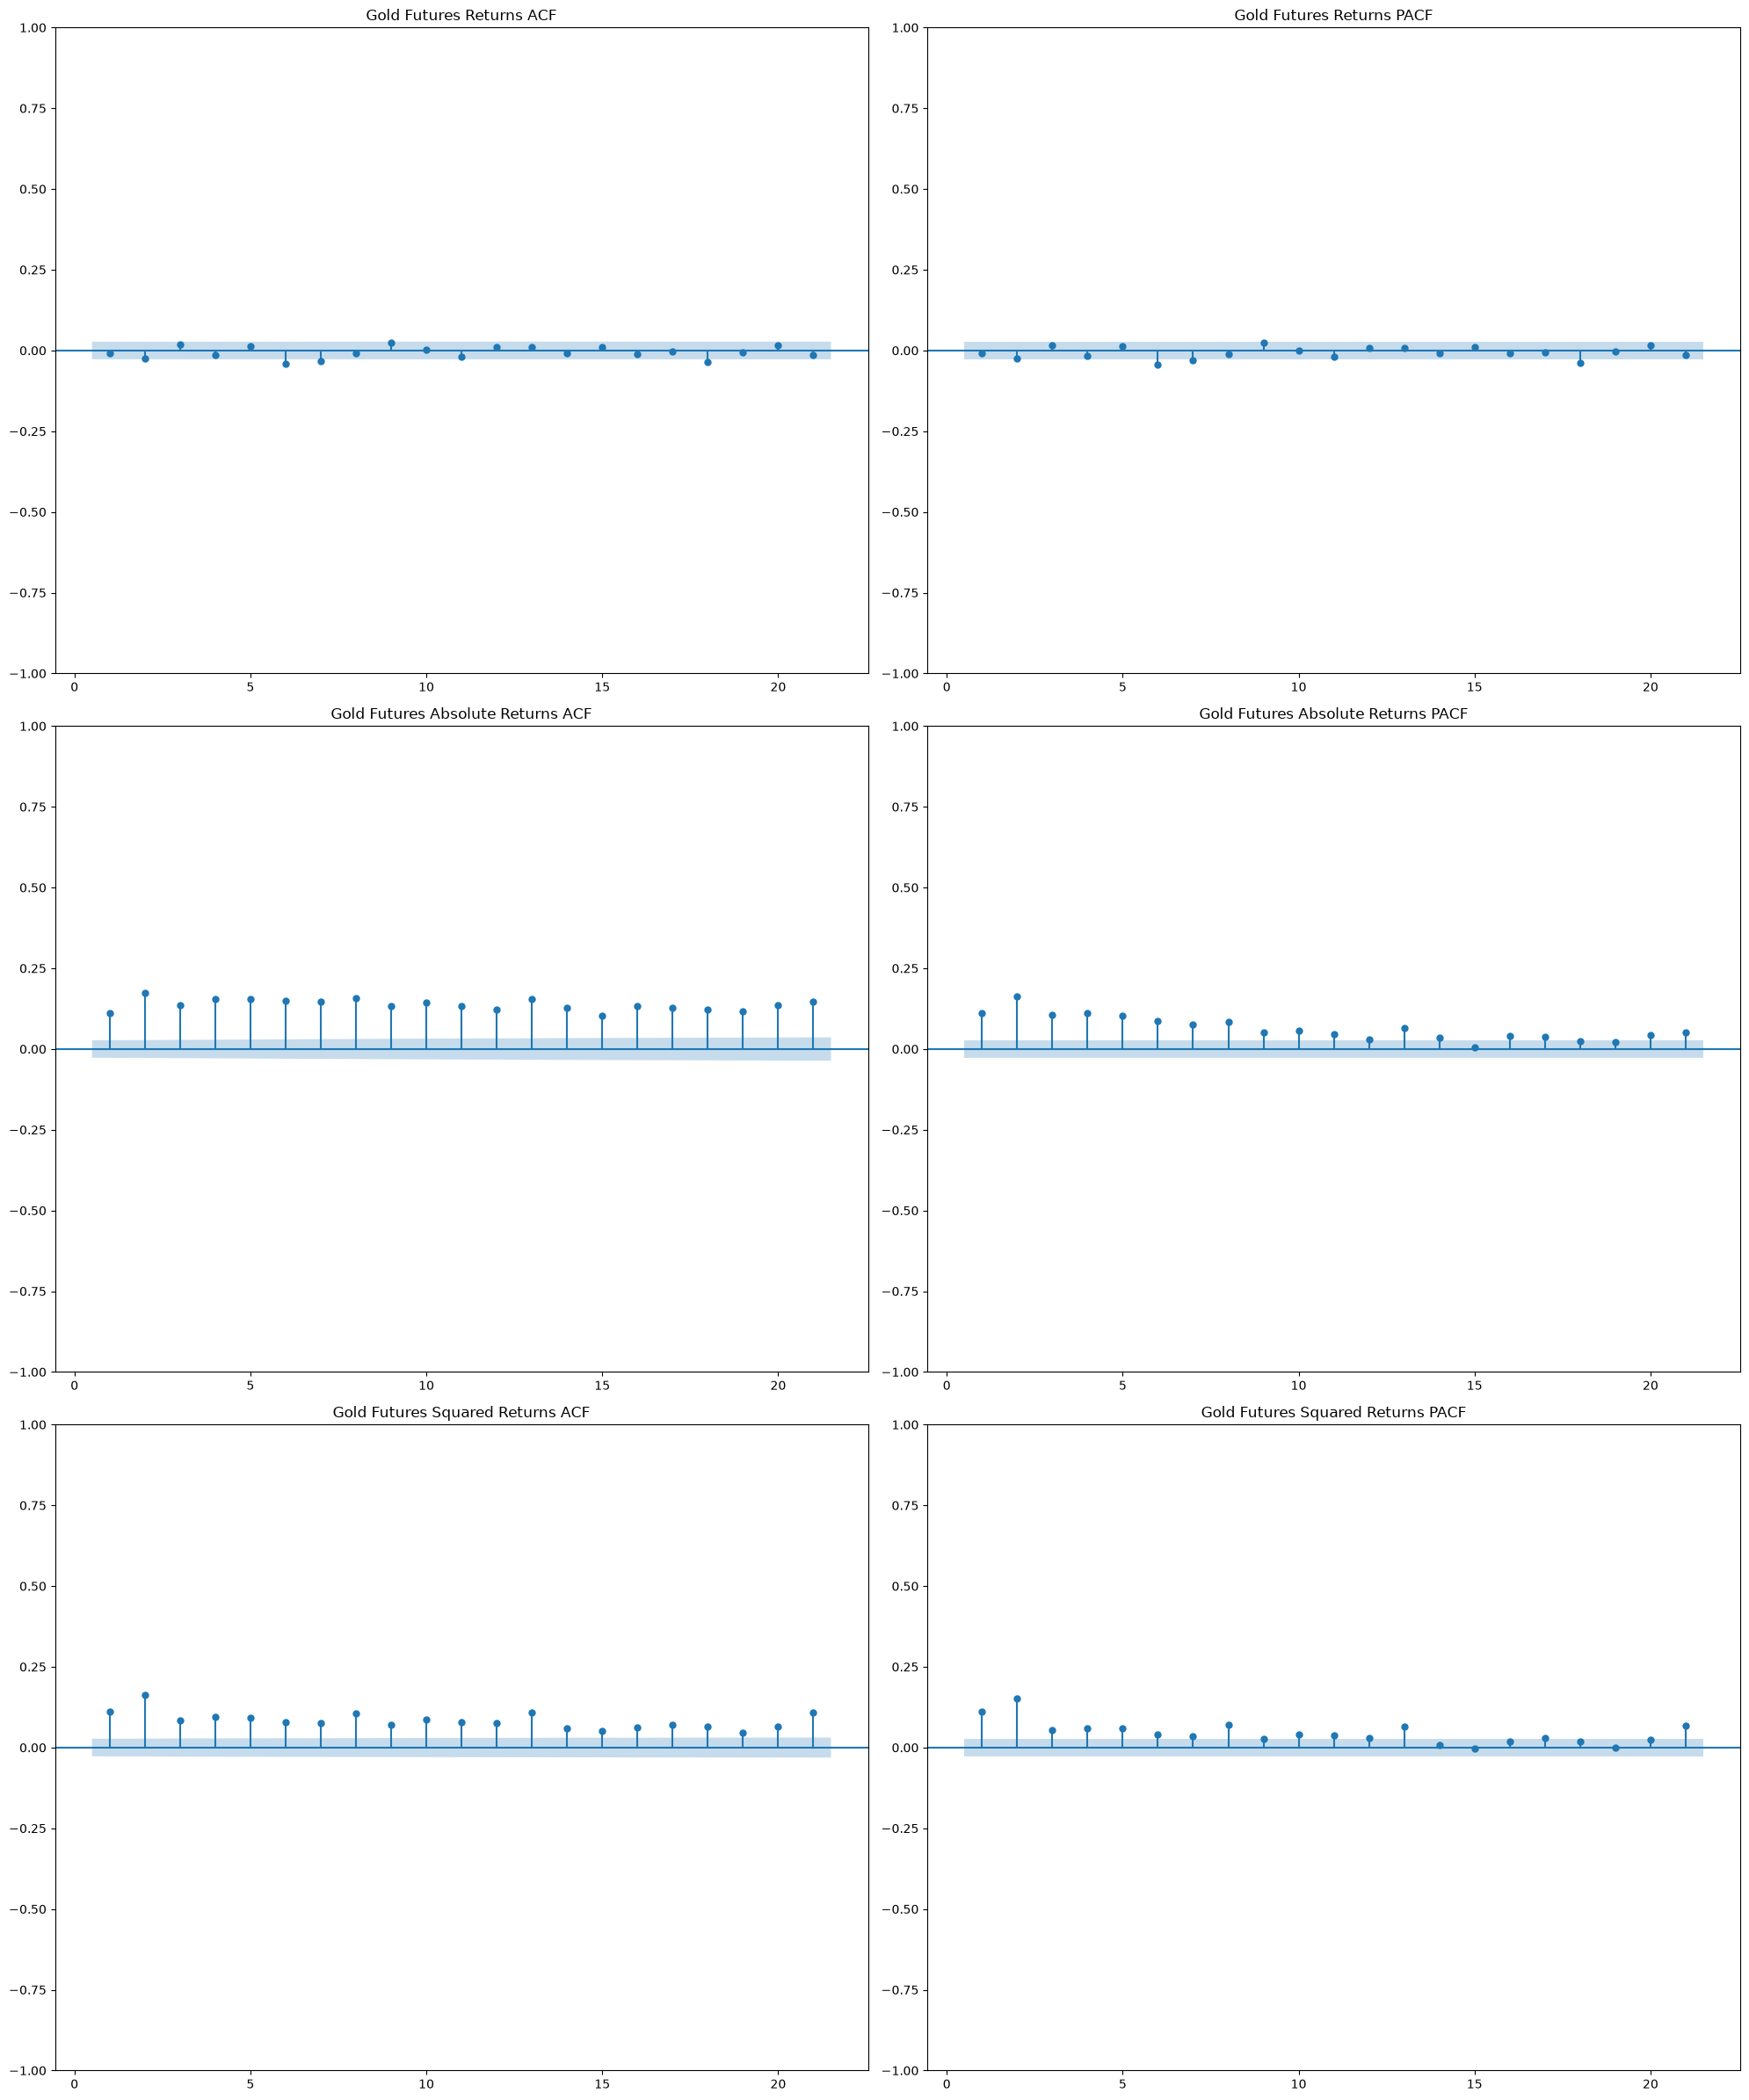

In [13]:
# Plot ACF and PACF. This shows if returns are autocorrelated, 
# meaning if there exists a time-dependent relationship between successive values. 
# The x-axis represents the time lag (i.e. number of days) between returns, 
# and nodes lying outside the confidence interval illustrate significant autocorrelation.

fig, ax = plt.subplots(3,2, figsize = (20,24))

plot_acf(Gold['Returns'], lags = 21, zero = False, ax = ax[0,0])
plot_pacf(Gold['Returns'], lags = 21, zero = False, ax = ax[0,1])
ax[0,0].set_title('Gold Futures Returns ACF')
ax[0,1].set_title('Gold Futures Returns PACF')
plot_acf(Gold['Abs_Returns'], lags = 21, zero = False, ax = ax[1,0])
plot_pacf(Gold['Abs_Returns'], lags = 21, zero = False, ax = ax[1,1])
ax[1,0].set_title('Gold Futures Absolute Returns ACF')
ax[1,1].set_title('Gold Futures Absolute Returns PACF')
plot_acf(Gold['Squared_Returns'], lags = 21, zero = False, ax = ax[2,0])
plot_pacf(Gold['Squared_Returns'], lags = 21, zero = False, ax = ax[2,1])
ax[2,0].set_title('Gold Futures Squared Returns ACF')
ax[2,1].set_title('Gold Futures Squared Returns PACF')

plt.tight_layout()
plt.show()

From above, autocorrelations are statistically significant in absolute and squared returns since most of the nodes within up to the 20-day lag are outside the confidence intervals. Since the latter is related to the construction of realized volatility, it shows us that volatility can potentially be autocorrelated. This observation gives us justification for using the GARCH model, because it accounts for the mean reversion, shock persistence and past volatility autocorrelation when forecasting future conditional volatility.

In [14]:
print("Returns ADF p-value:", adfuller(Gold['Returns'])[1]) # p < 0.05 means stationary
print("Returns KPSS p-value:", kpss(Gold['Returns'], regression = 'c')[1]) #p > 0.05 means stationary

Returns ADF p-value: 0.0
Returns KPSS p-value: 0.1


In [15]:
# Compute trailing annualized realized volatility, in percentage points. These are the inputs.
Gold['RVOL_21d'] = np.sqrt(252 * Gold['Returns'].pow(2).rolling(21).mean())
Gold['RVOL_42d'] = np.sqrt(252 * Gold['Returns'].pow(2).rolling(42).mean())
Gold['RVOL_63d'] = np.sqrt(252 * Gold['Returns'].pow(2).rolling(63).mean())

# Roll the original trailing 21-day annualized realized volatility forward by a month as a proxy for future 21-day volatility.
# This is the target to compare against.
Gold['Future_RVOL_21d'] = Gold['RVOL_21d'].shift(-21)

Gold.dropna(subset = ['RVOL_21d', 'RVOL_42d', 'RVOL_63d', 'Future_RVOL_21d'], inplace = True)

Gold

,Close,Returns,Abs_Returns,Squared_Returns,RVOL_21d,RVOL_42d,RVOL_63d,Future_RVOL_21d
Date,,,,,,,,
2006-04-04,586.000000,-0.578532,0.578532,0.334700,16.303353,20.412660,20.023343,24.094617
2006-04-05,587.900024,0.323712,0.323712,0.104789,16.283827,20.310126,19.997695,24.412922
2006-04-06,595.200012,1.234060,1.234060,1.522903,15.549943,20.498408,19.944352,24.140013
2006-04-07,588.400024,-1.149047,1.149047,1.320310,15.937220,18.913302,19.436395,26.172321
2006-04-10,597.599976,1.551456,1.551456,2.407017,16.434774,19.287166,19.377189,25.702420
...,...,...,...,...,...,...,...,...
2026-06-25,4047.600098,0.963218,0.963218,0.927789,31.165413,26.025654,26.908646,21.075370
2026-06-26,4096.299805,1.195994,1.195994,1.430402,31.161534,26.075087,25.838170,20.921205
2026-06-29,4038.899902,-1.411173,1.411173,1.991408,31.295445,25.916715,25.457946,20.343115


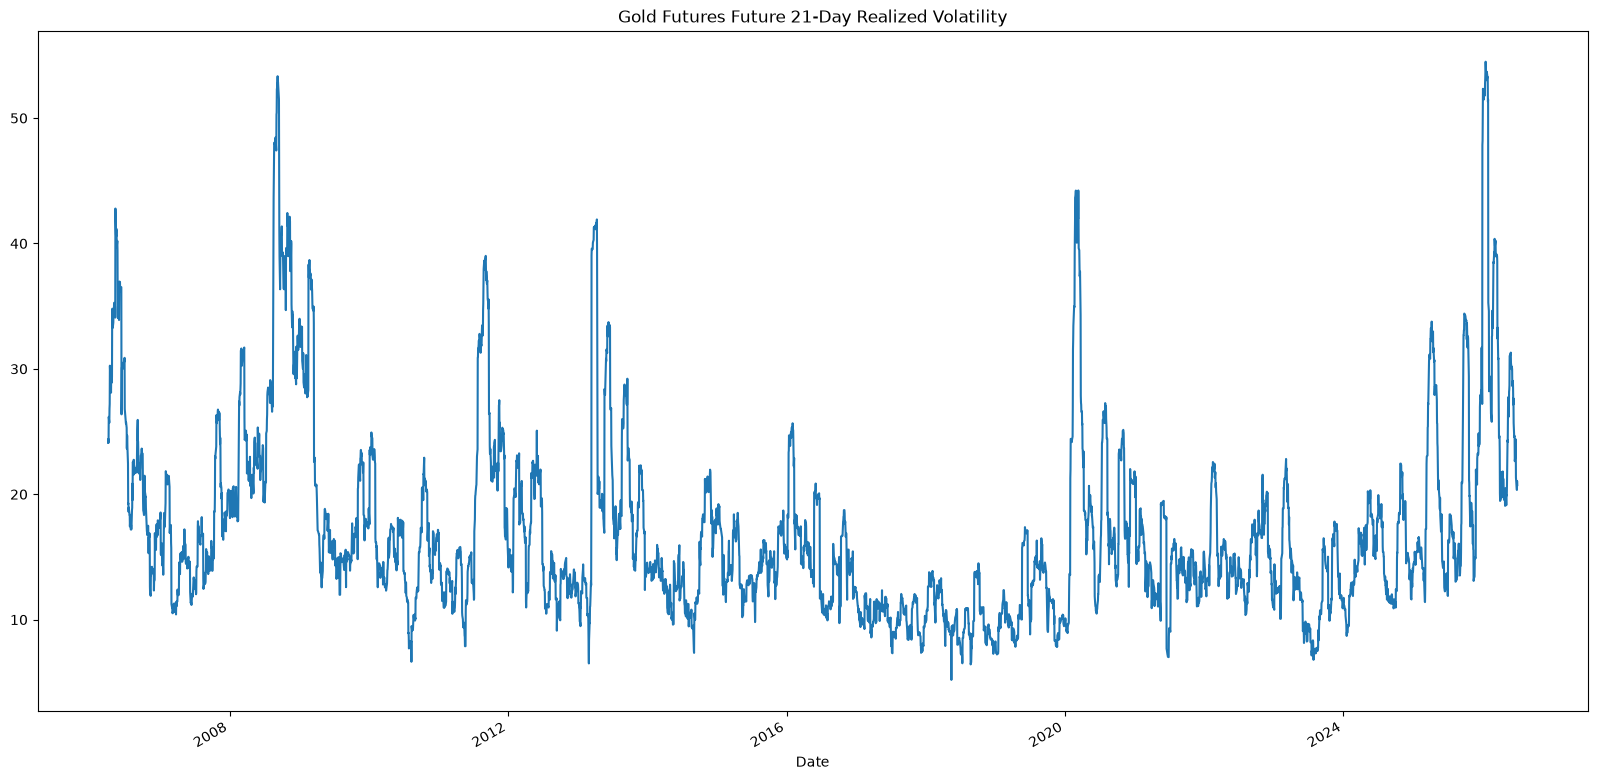

In [16]:
Gold["Future_RVOL_21d"].plot(title = "Gold Futures Future 21-Day Realized Volatility", figsize = (20, 10));
plt.show()

# Part 3: Training Models and Hyperparameter Tuning

For GARCH, data is split into a trainining subset before 2025 and a corresponding testing subset onwards. No validation period is considered. Parameters chosen are the standard GARCH(1, 1) specification, and an expanding window approach is used by continuously incorporating new information on each date in the test set.

In [17]:
GARCH_forecasts = []

test_date = Gold.index[Gold.index >= '2025-01-01']

for date in test_date:

    training_data = Gold.loc[Gold.index <= date, "Returns"]

    model = arch_model(
        training_data,
        mean = "Constant",
        vol = "GARCH",
        p = 1,
        q = 1,
        dist = "t",
        rescale = False
    )

    result = model.fit(disp = "off")

    # forecast next 21 days
    forecast = result.forecast(horizon = 21)

    variance = forecast.variance.iloc[-1]

    # convert variance to volatility
    predicted_vol = np.sqrt(variance.mean() * 252)

    actual_vol = Gold.loc[date, "Future_RVOL_21d"]

    GARCH_forecasts.append({"date": date,"predicted_rvol_21d": predicted_vol,"actual_rvol_21d": actual_vol})

GARCH_results = pd.DataFrame(GARCH_forecasts)
GARCH_results["absolute_error"] = (GARCH_results["predicted_rvol_21d"] - GARCH_results["actual_rvol_21d"]).abs()

GARCH_results.set_index("date", inplace = True)

GARCH_results

,predicted_rvol_21d,actual_rvol_21d,absolute_error
date,,,
2025-01-02,17.162130,14.425412,2.736717
2025-01-03,16.982000,14.482277,2.499723
2025-01-06,16.749921,14.597722,2.152199
2025-01-07,16.593448,14.540104,2.053344
2025-01-08,16.356611,14.570707,1.785904
...,...,...,...
2026-06-25,28.572017,21.075370,7.496646
2026-06-26,28.227580,20.921205,7.306375
2026-06-29,28.034694,20.343115,7.691579


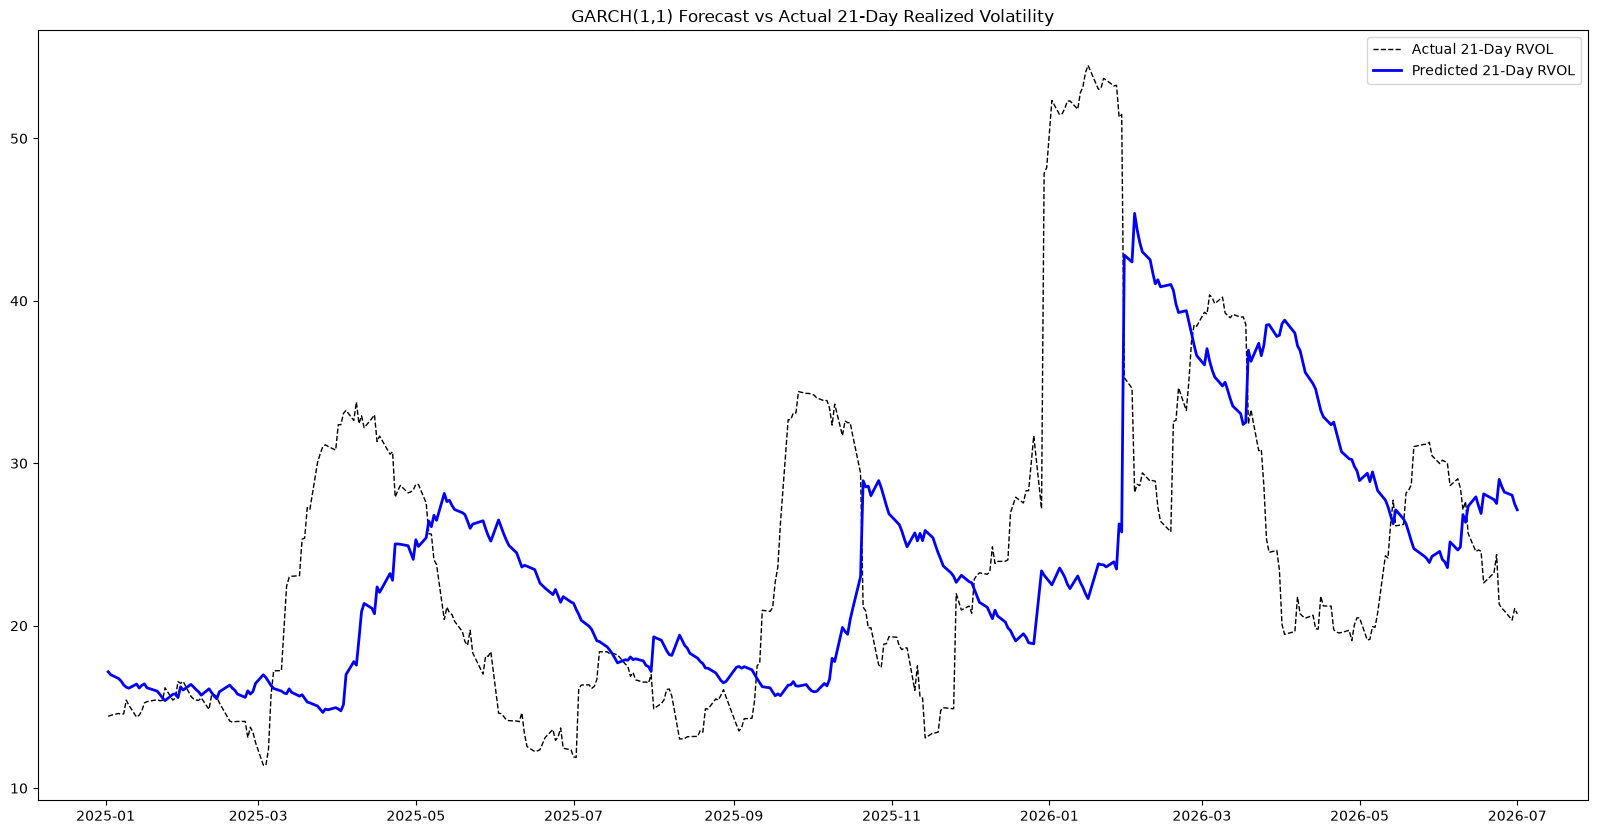

In [18]:
fig, ax = plt.subplots(figsize = (20, 10))
ax.plot(GARCH_results["actual_rvol_21d"], label = "Actual 21-Day RVOL", linewidth = 1, color = "black", linestyle = "--")
ax.plot(GARCH_results["predicted_rvol_21d"], label = "Predicted 21-Day RVOL", linewidth = 2, color = "blue")
ax.set_title("GARCH(1,1) Forecast vs Actual 21-Day Realized Volatility")
ax.legend()
plt.show()

[*********************100%***********************]  1 of 1 completed


<Axes: title={'center': 'USD_index'}, xlabel='Date'>

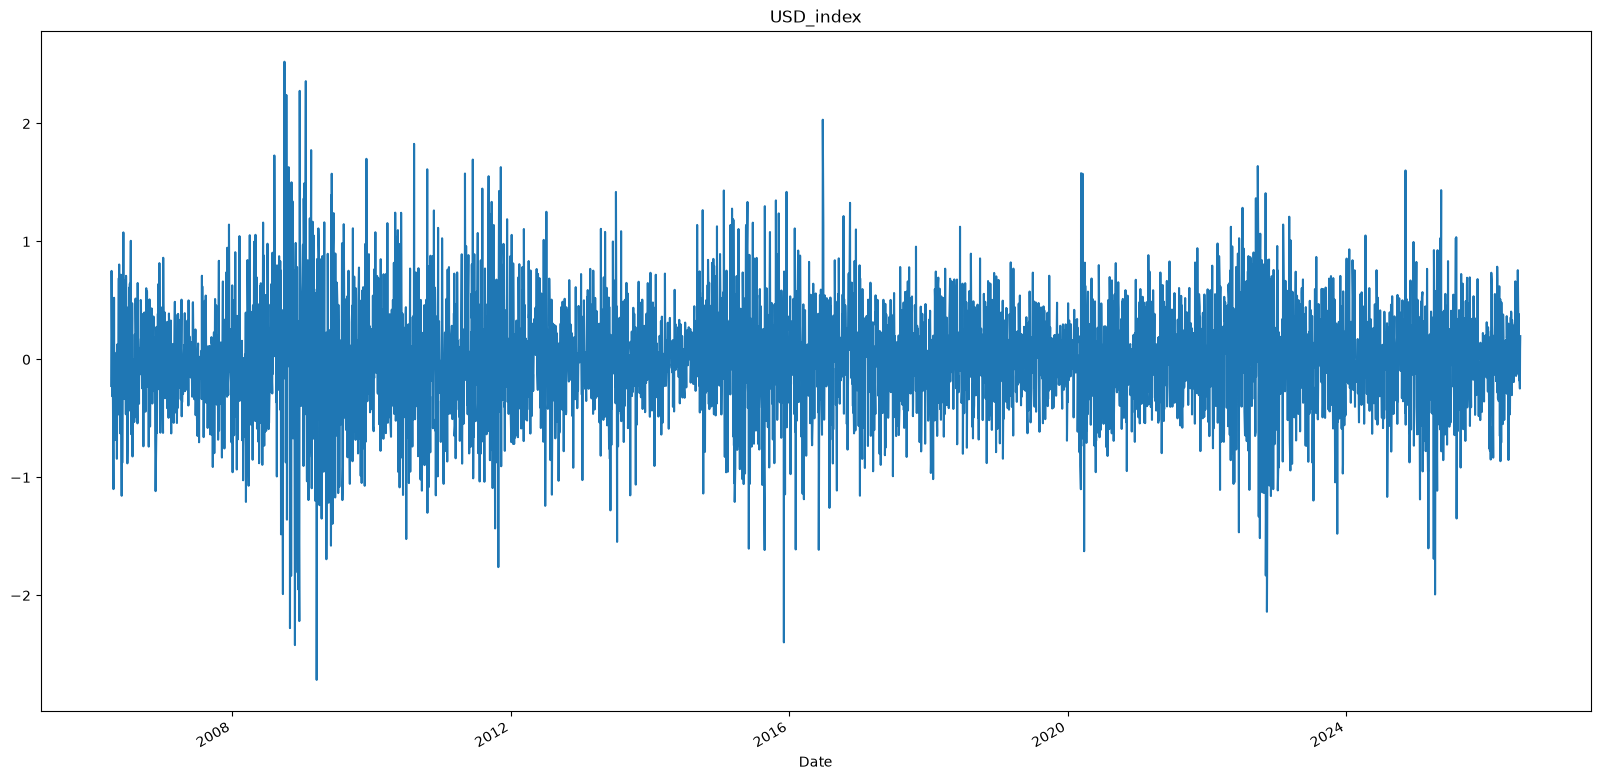

In [19]:
usd = yf.download("DX-Y.NYB", start = "2006-01-01", end = "2026-08-01", auto_adjust = False)

Gold["USD_index"] = (100 * np.log(usd['Close'].reindex(Gold.index).ffill())).diff()

Gold["USD_index"].plot(title = "USD_index", figsize = (20, 10))

[*********************100%***********************]  1 of 1 completed


<Axes: title={'center': 'S&P 500 Return'}, xlabel='Date'>

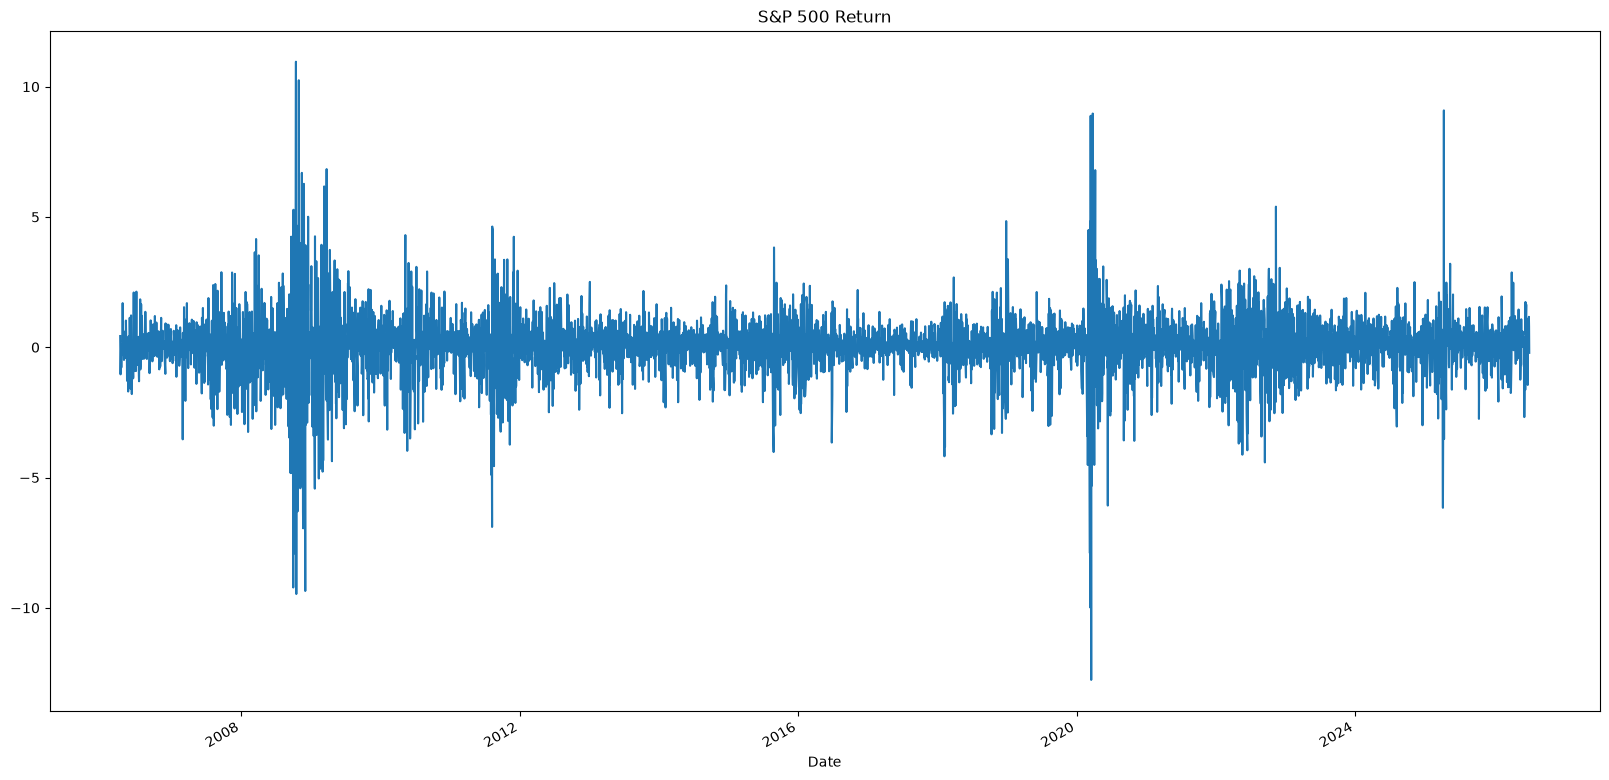

In [20]:
sp500 = yf.download("^GSPC", start = "2006-01-01", end = "2026-08-01", auto_adjust = True)

Gold["Equity_Return"] = 100 * np.log(sp500["Close"].reindex(Gold.index).ffill()).diff()

Gold['Equity_Return'].plot(title = "S&P 500 Return", figsize = (20, 10))

[*********************100%***********************]  1 of 1 completed


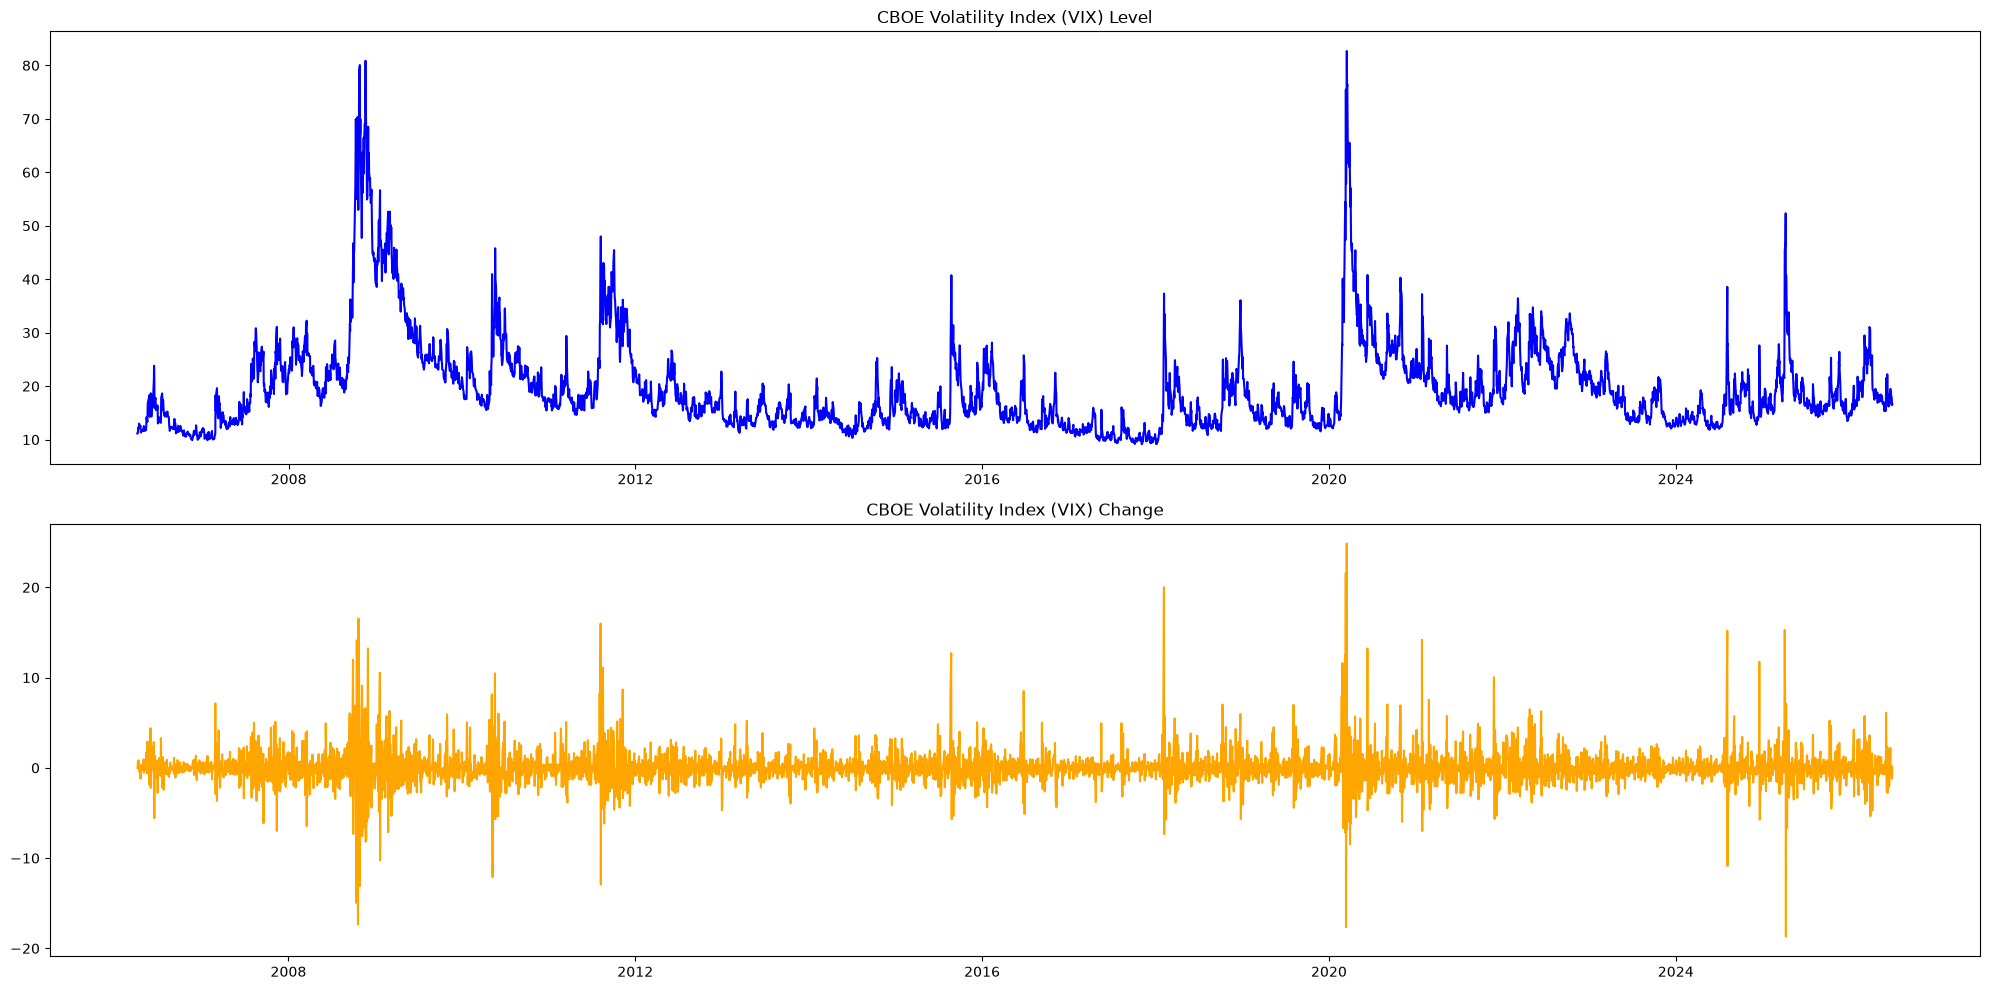

In [21]:
vix = yf.download("^VIX", start = "2006-01-01", end = "2026-08-01", auto_adjust = False)

Gold['VIX_Level'] = vix['Close'].reindex(Gold.index).ffill()
Gold['VIX_Change'] = Gold['VIX_Level'].diff()

fig, ax = plt.subplots(2, 1, figsize = (20, 10))
ax[0].plot(Gold['VIX_Level'], color = 'blue')
ax[0].set_title('CBOE Volatility Index (VIX) Level')
ax[1].plot(Gold['VIX_Change'], color = 'orange')
ax[1].set_title('CBOE Volatility Index (VIX) Change')
plt.tight_layout()
plt.show()

[*********************100%***********************]  1 of 1 completed


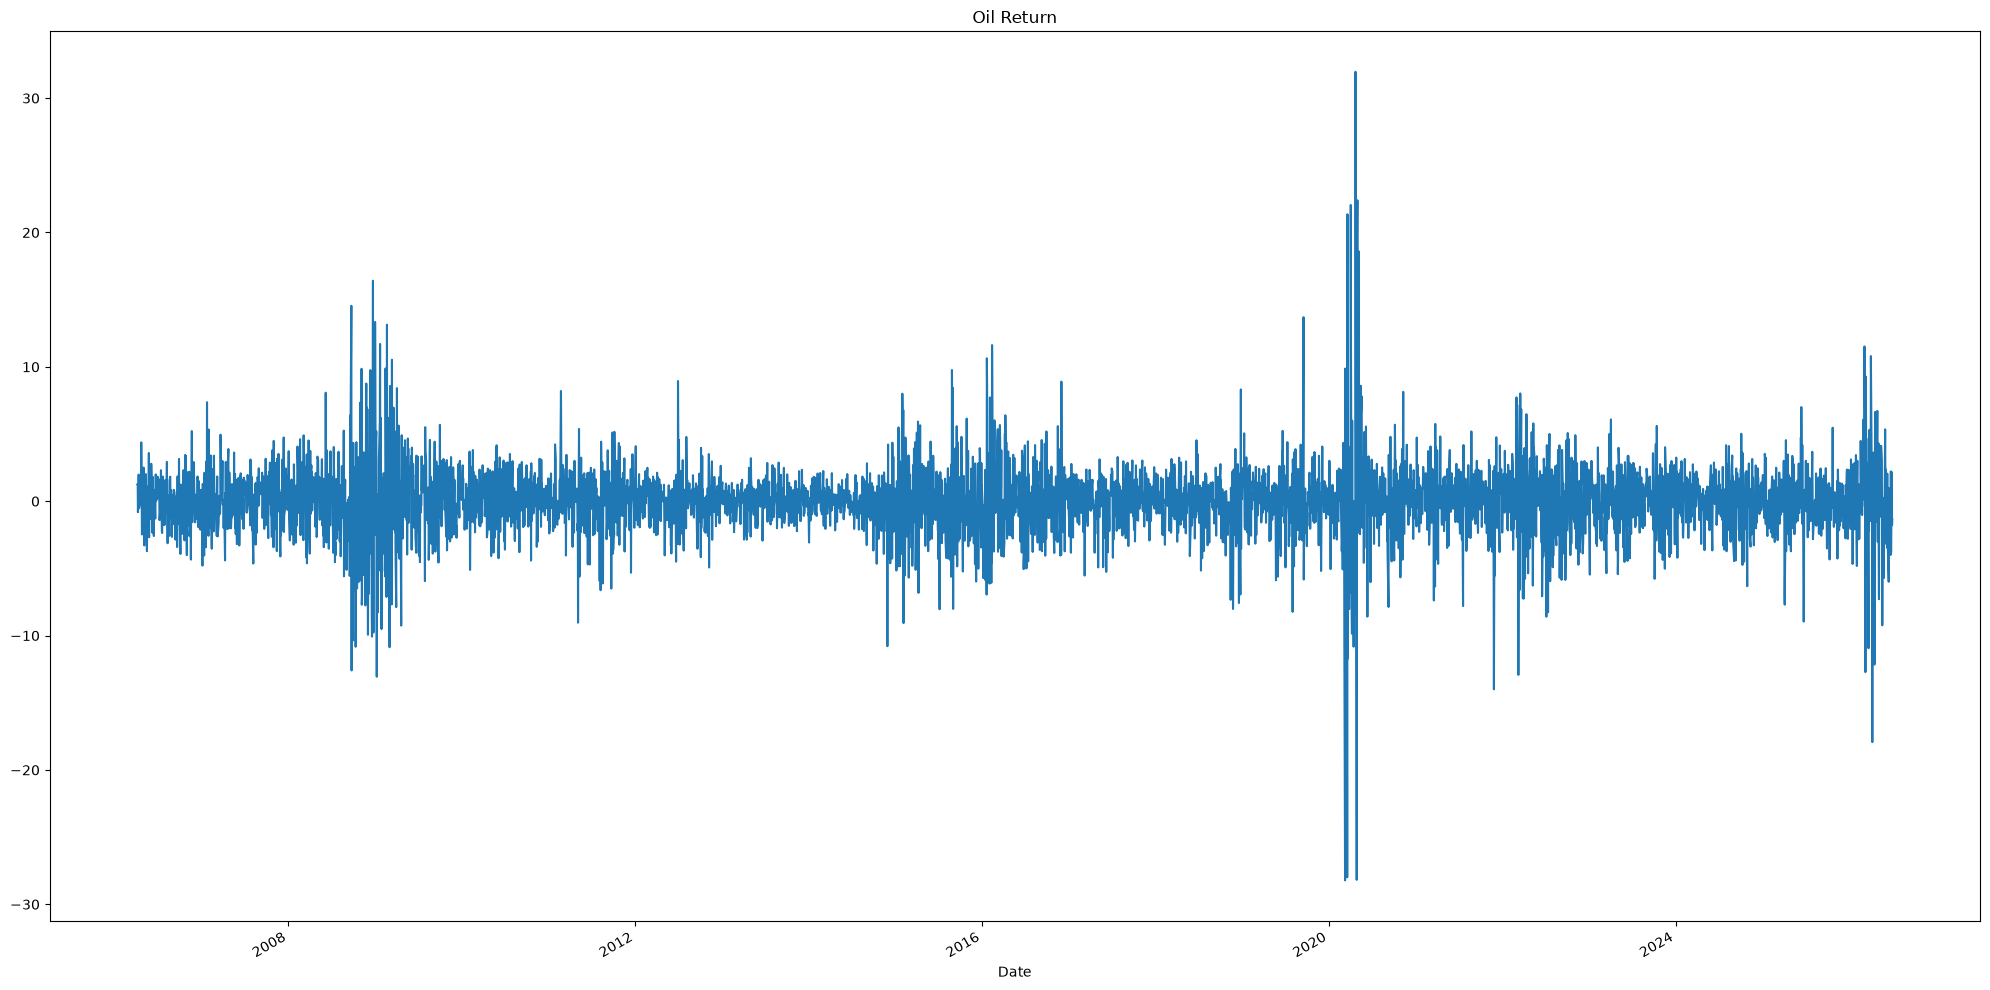

In [22]:
oil = yf.download("CL=F", start = "2006-01-01", end = "2026-08-01", auto_adjust = False)

Gold['Oil_Returns'] = (100 * np.log(oil['Close'].reindex(Gold.index).ffill())).diff().ffill()
Gold['Oil_Returns'].plot(title = "Oil Return", figsize = (20, 10))
plt.tight_layout()
plt.show()

[*********************100%***********************]  1 of 1 completed


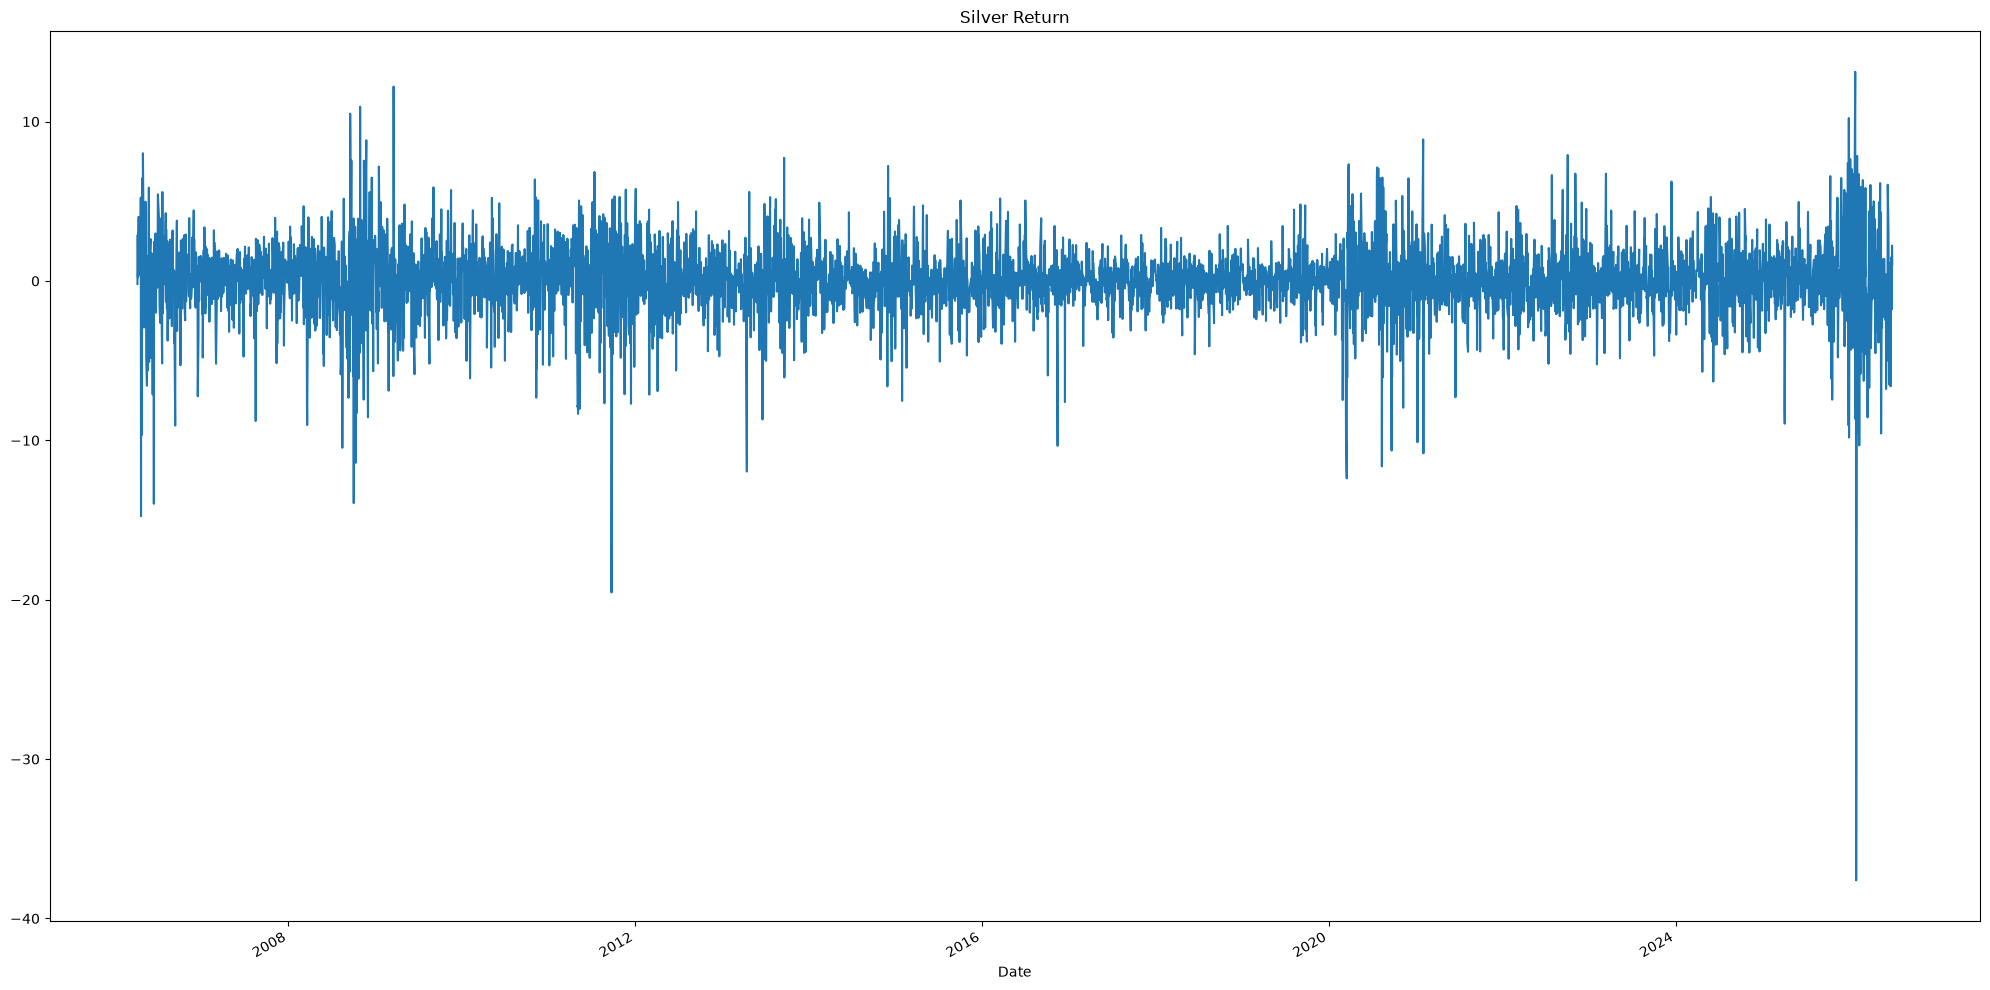

In [23]:
silver = yf.download("SI=F", start = "2006-01-01", end = "2026-08-01", auto_adjust = False)

Gold['Silver_Returns'] = 100 * np.log(silver['Close'].reindex(Gold.index).ffill()).diff()
Gold['Silver_Returns'].plot(title = "Silver Return", figsize = (20, 10))
plt.tight_layout()
plt.show()

In [24]:
Gold.dropna(subset = ['USD_index', 'Equity_Return', 'VIX_Change', 'Oil_Returns', 'Silver_Returns'], inplace = True)

In [25]:
candidate_features = np.array(['Returns', 'Abs_Returns', 'Squared_Returns', 'RVOL_21d', 'RVOL_42d', 'RVOL_63d', "USD_index", "Equity_Return", 'VIX_Level', 'VIX_Change', 'Oil_Returns', 'Silver_Returns'])
features = candidate_features[:] # Select the set of features for LSTM model

In [26]:
Gold["Target_End"] = Gold.index.to_series().shift(-21) # Used for purged data splitting to prevent data leakage

x_scaler = StandardScaler()
y_scaler = StandardScaler()

train_mask = Gold['Target_End'] < '2023-01-01'

x_scaler.fit(Gold.loc[train_mask, features])

y_scaler.fit(Gold.loc[train_mask, ['Future_RVOL_21d']])

X_scaled = x_scaler.transform(Gold[features])

y_scaled = y_scaler.transform(Gold[['Future_RVOL_21d']]).flatten()

print(X_scaled.shape, y_scaled.shape, Gold.shape)

(5091, 12) (5091,) (5091, 15)


In [27]:
sequence_length = 84

X = []
y = []
dates = []
target_end_dates = []

for i in range(sequence_length - 1, len(Gold)):

    X.append(X_scaled[i - sequence_length + 1: i + 1])

    y.append(y_scaled[i])

    dates.append(Gold.index[i])

    target_end_dates.append(Gold["Target_End"].iloc[i])

X = np.array(X)
y = np.array(y)
dates = pd.to_datetime(dates)
target_end_dates = pd.to_datetime(target_end_dates)


In [28]:
train_idx = target_end_dates < pd.Timestamp("2023-01-01")

val_idx = ((dates >= pd.Timestamp("2023-01-01")) & (target_end_dates < pd.Timestamp("2025-01-01")))

test_idx = dates >= pd.Timestamp("2025-01-01")

In [29]:
X_train = X[train_idx]
y_train = y[train_idx]

X_val = X[val_idx]
y_val = y[val_idx]

X_test = X[test_idx]
y_test = y[test_idx]

In [30]:
def create_model(architecture = (64, 32), learning_rate = 0.0001, dropout = 0.2, l2 = 0.0001, optimizer = tf.keras.optimizers.Adam, momentum = 0.0):

    model = Sequential()

    for i, units in enumerate(architecture):
        return_sequences = True if i < len(architecture) - 1 else False
        if i == 0:
            model.add(LSTM(units = units, input_shape = (X_train.shape[1], X_train.shape[2]), kernel_regularizer = tf.keras.regularizers.l2(l2), return_sequences = return_sequences))
        else:
            model.add(LSTM(units = units, return_sequences = return_sequences, kernel_regularizer = tf.keras.regularizers.l2(l2)))
        model.add(Dropout(dropout))

    model.add(Dense(units = 1))

    if optimizer == "adam":
        opt = tf.keras.optimizers.Adam(learning_rate = learning_rate)

    elif optimizer == "rmsprop":
        opt = tf.keras.optimizers.RMSprop(learning_rate = learning_rate)

    elif optimizer == "sgd":
        opt = tf.keras.optimizers.SGD(learning_rate = learning_rate, momentum = momentum)

    model.compile(optimizer = opt, loss = "mse")

    return model

In [31]:
regressor = KerasRegressor(model = create_model, epochs = 100, verbose = 0, shuffle = False)

In [32]:
param_grid = [
    {
        "model__optimizer": ["adam", "rmsprop"],
        "model__architecture": [
        (16,),
        (32,),
        (64,),
        (64, 32),
        (32, 16),
        (64, 32, 16)
        ],
        "model__learning_rate": [0.0005, 0.001, 0.005],
        "model__dropout": [0, 0.1, 0.2],
        "model__l2": [0, 1e-3],
        "batch_size": [16, 32, 64],
    },

    {
        "model__optimizer": ["sgd"],   
        "model__architecture": [
        (16,),
        (32,),
        (64,),
        (64, 32),
        (32, 16),
        (64, 32, 16)
        ],
        "model__learning_rate": [0.001, 0.005, 0.01],
        "model__momentum": [0.0, 0.5, 0.9],
        "model__dropout": [0.1, 0.2],
        "model__l2": [0, 0.001],
        "batch_size": [16, 32, 64]
    }
]

In [33]:
# Combine training and validation data
X_search = np.concatenate([X_train, X_val], axis = 0)
y_search = np.concatenate([y_train, y_val], axis = 0)

# -1: always training
#  0: validation fold
test_fold = np.concatenate([
    np.full(len(X_train), -1),
    np.zeros(len(X_val), dtype = int)
])

fixed_split = PredefinedSplit(test_fold)

grid = GridSearchCV(
    estimator = regressor,
    param_grid = param_grid,
    cv = fixed_split,
    scoring = "neg_mean_squared_error",
    n_jobs = -1,
    verbose = 1,
    refit = True,
    return_train_score = True
)

grid.fit(X_search, y_search)

Fitting 1 folds for each of 1296 candidates, totalling 1296 fits


KeyboardInterrupt: 

In [ ]:
grid.best_params_

{'batch_size': 16,
 'model__architecture': (16,),
 'model__dropout': 0.2,
 'model__l2': 0,
 'model__learning_rate': 0.005,
 'model__momentum': 0.0,
 'model__optimizer': 'sgd'}

In [ ]:
grid.best_score_

np.float64(-0.21799543411081274)

In [ ]:
best_model = grid.best_estimator_

test_pred_scaled = best_model.predict(X_test).reshape(-1, 1)

RV_Prediction_LSTM = y_scaler.inverse_transform(test_pred_scaled).ravel()

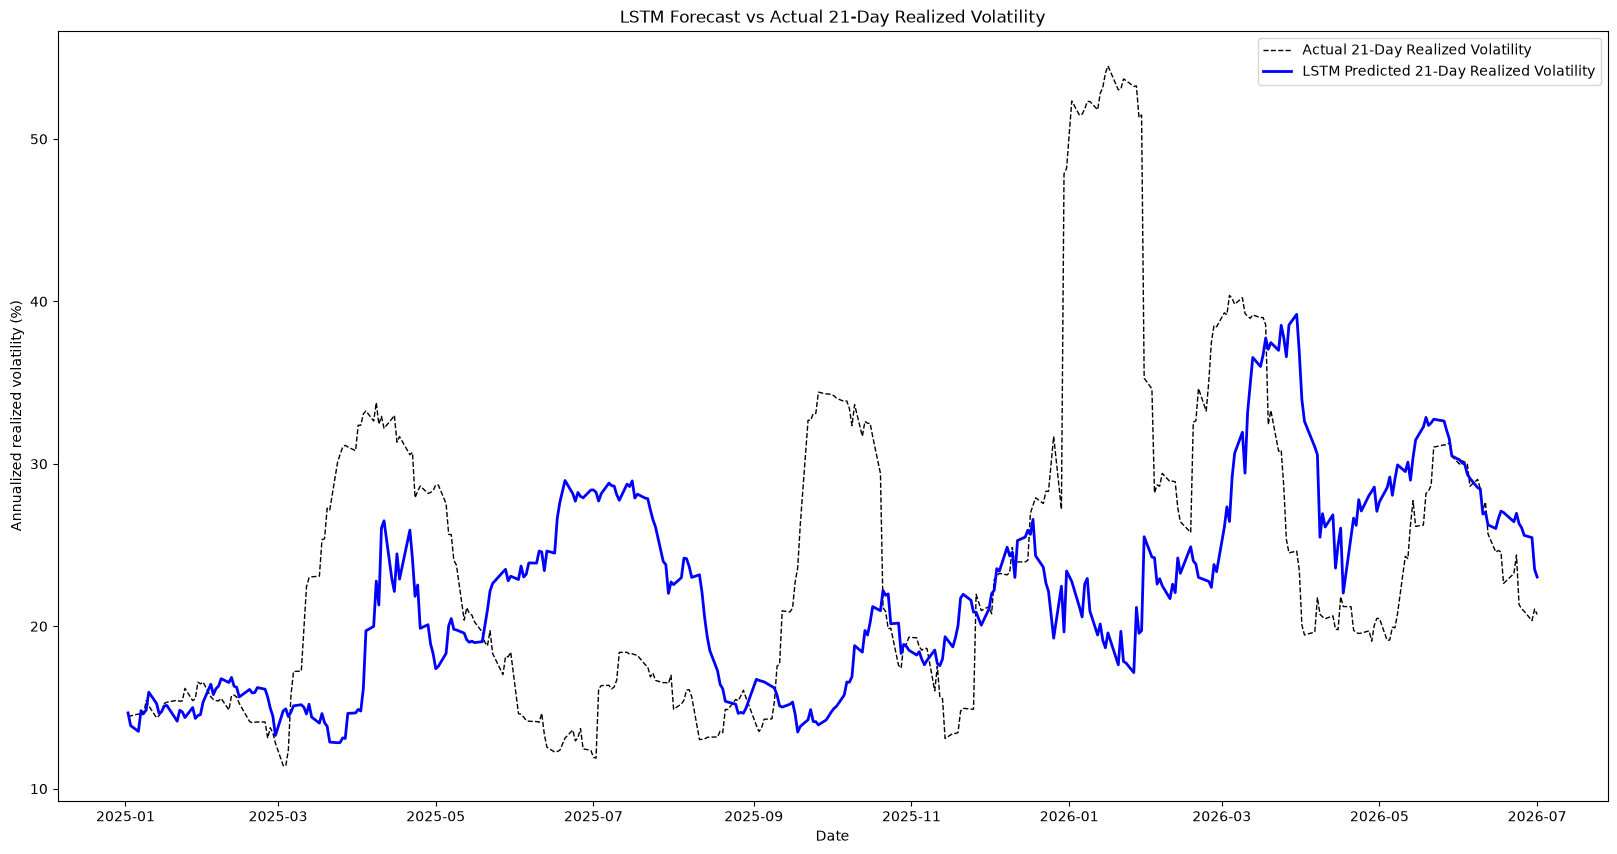

In [ ]:
fig, ax = plt.subplots(figsize = (20, 10))

actual_rvol = Gold.loc[dates[test_idx], "Future_RVOL_21d"]

ax.plot(dates[test_idx], actual_rvol, label = "Actual 21-Day Realized Volatility", linewidth = 1, color = "black", linestyle = "--")
ax.plot(dates[test_idx], RV_Prediction_LSTM, label = "LSTM Predicted 21-Day Realized Volatility", linewidth = 2, color = "blue")
ax.set_title("LSTM Forecast vs Actual 21-Day Realized Volatility")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized realized volatility (%)")
ax.legend()
plt.show()

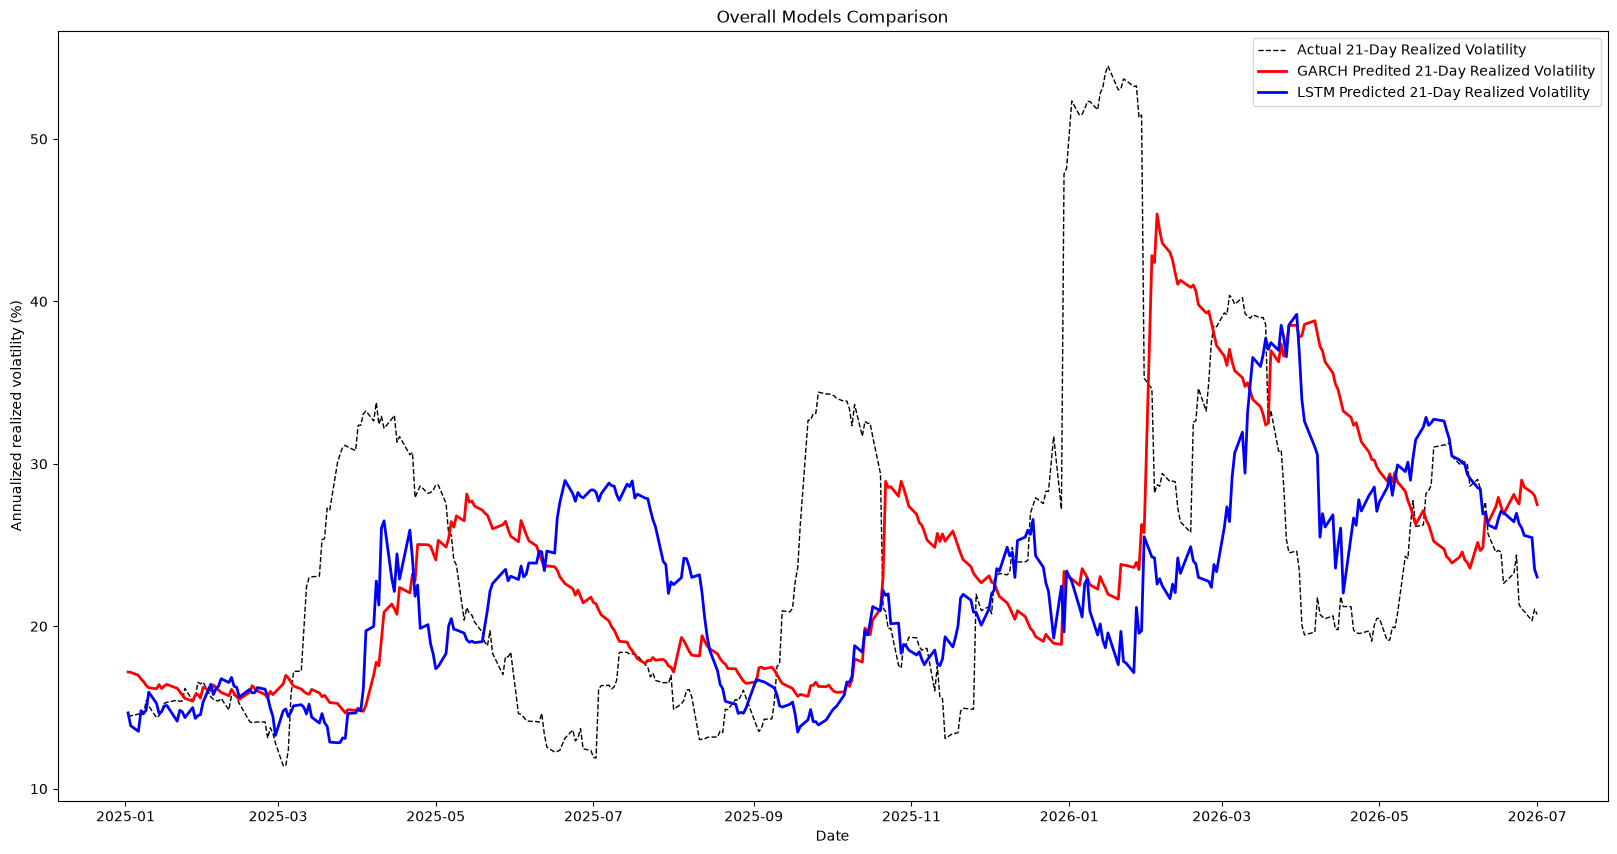

In [ ]:
fig, ax = plt.subplots(figsize = (20, 10))

actual_rvol = Gold.loc[dates[test_idx], "Future_RVOL_21d"]
RV_Prediction_GARCH = GARCH_results["predicted_rvol_21d"]

ax.plot(dates[test_idx], actual_rvol, label = "Actual 21-Day Realized Volatility", linewidth = 1, color = "black", linestyle = "--")
ax.plot(dates[test_idx], RV_Prediction_GARCH, label = "GARCH Predited 21-Day Realized Volatility", linewidth = 2, color = "red")
ax.plot(dates[test_idx], RV_Prediction_LSTM, label = "LSTM Predicted 21-Day Realized Volatility", linewidth = 2, color = "blue")
ax.set_title("Overall Models Comparison")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized realized volatility (%)")
ax.legend()
plt.show()

In [ ]:
def qlike (true_vol, predicted_vol):
    eps = 1e-12 # Prevents division by zero and taking log of zero

    true_var = np.maximum(np.asarray(true_vol)**2, eps)
    predicted_var = np.maximum(np.asarray(predicted_vol)**2, eps)

    ratio = true_var / predicted_var
    return np.mean(ratio - np.log(ratio) - 1)

def bias(true_vol, predicted_vol):
    return np.mean(np.asarray(predicted_vol) - np.asarray(true_vol))

In [ ]:
metrics = pd.DataFrame(index = ['RMSE', 'MAE', 'QLIKE', 'BIAS'], columns = ['GARCH', 'LSTM'])

GARCH_RMSE = root_mean_squared_error(actual_rvol, RV_Prediction_GARCH)
GARCH_MAE = mean_absolute_error(actual_rvol, RV_Prediction_GARCH)
GARCH_QLIKE = qlike(actual_rvol, RV_Prediction_GARCH)
GARCH_BIAS = bias(actual_rvol, RV_Prediction_GARCH)
LSTM_RMSE = root_mean_squared_error(actual_rvol, RV_Prediction_LSTM)
LSTM_MAE = mean_absolute_error(actual_rvol, RV_Prediction_LSTM)
LSTM_QLIKE = qlike(actual_rvol, RV_Prediction_LSTM)
LSTM_BIAS = bias(actual_rvol, RV_Prediction_LSTM)

metrics['GARCH'] = np.array([GARCH_RMSE, GARCH_MAE, GARCH_QLIKE, GARCH_BIAS])
metrics['LSTM'] = np.array([LSTM_RMSE, LSTM_MAE, LSTM_QLIKE, LSTM_BIAS])

metrics

,GARCH,LSTM
RMSE,10.897076,11.175499
MAE,8.205291,7.923445
QLIKE,0.433991,0.554853
BIAS,-0.491755,-2.007974
